In [22]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from typing import TypedDict
from dotenv import load_dotenv

In [23]:
load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [44]:
class BatsmanState(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int

    sr: float
    bpb: float
    boundary_percent: float
    summary: str

print(type(BatsmanState))

<class 'typing._TypedDictMeta'>


In [25]:
def calculate_bpb(state: BatsmanState) -> BatsmanState:
    bpb = ((state['fours'] + state['sixes']) / (state['balls']))
    return {'bpb': bpb}

In [26]:
def calculate_sr(state: BatsmanState) -> BatsmanState:
    sr = ((state['runs']) / (state['balls'])) * 100
    return {'sr': sr}

In [27]:
def calculte_boundary_percentage(state: BatsmanState) -> BatsmanState:
    boundary_runs = (state['fours'] * 4) + (state['sixes'] * 6)
    boundary_percent = (boundary_runs / state['runs']) * 100
    return {'boundary_percent': boundary_percent}

In [66]:
def summary(state: BatsmanState) -> BatsmanState:
    prompt = PromptTemplate(
        template = "Given is the data of a inning for a batsman. Generate a summary for this inning of his/her. \nData:- {data}",
        input_variables=["data"]
    )

    result = llm.invoke(prompt.invoke({"data": state}))
    return {"summary": result.content}


In [67]:
graph = StateGraph(BatsmanState)

# add nodes
graph.add_node("calculate_bpb", calculate_bpb)
graph.add_node("calculate_sr", calculate_sr)
graph.add_node("calculte_boundary_percentage", calculte_boundary_percentage)
graph.add_node("summary", summary)

# add edges
graph.add_edge(START, "calculate_bpb")
graph.add_edge(START, "calculate_sr")
graph.add_edge(START, "calculte_boundary_percentage")

graph.add_edge("calculate_bpb", "summary")
graph.add_edge("calculate_sr", "summary")
graph.add_edge("calculte_boundary_percentage", "summary")

graph.add_edge("summary", END)

# compile graph
workflow = graph.compile()

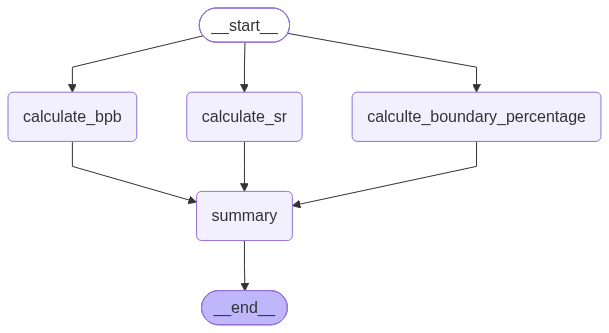

In [68]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [69]:
initial_state = {"runs": 120, "balls": 40, "fours": 12, "sixes": 8}
final_state = llm.invoke(str(initial_state))
print(final_state)

content=[{'type': 'text', 'text': 'Here is a breakdown and analysis of this incredible batting performance (likely from a T20 or T10 cricket match):\n\n*   **Strike Rate:** **300.00** *(120 runs off 40 balls)* — This is phenomenal hitting. \n*   **Runs scored in boundaries:** **96 runs** *(12 fours = 48 runs, 8 sixes = 48 runs)*\n*   **Runs scored in running:** **24 runs** *(120 total - 96 boundary runs)*\n*   **Boundary Percentage:** **80%** of the total runs came from boundaries (fours and sixes).\n*   **Total Boundaries:** **20 hits** to or over the fence out of 40 balls faced (meaning the batter hit a boundary on **50%** of the balls they faced).\n\nIn short: This is a blistering, match-winning century!', 'extras': {'signature': 'EmAKXgFpFH0TsVZ0VF5pOvaUQ+KJKS38lTK80KAIPIIPvkuW3YD80qPLXrfgcfHVbgJkd78PZMc1imhvGdRu3pPs4vEAuFu1akDTC9BAiKanRJSF3UFPfhkcfY0k63jBpn0='}}] additional_kwargs={} response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings